# Workflow Data Science : Analyse des Appels d'Offres (Binôme 1)

Ce notebook appelle directement les 3 scripts du dossier `source/` (`scraper.py`, `nettoyage.py`, `visualisation.py`) avec uniquement les notions vues en cours.

In [1]:
import sys
from pathlib import Path

# Ajouter le dossier source/ au chemin Python pour importer nos fonctions
SOURCE_DIR = Path("..").resolve() / "source"
if str(SOURCE_DIR) not in sys.path:
    sys.path.append(str(SOURCE_DIR))

import pandas as pd
from IPython.display import Image, display

from scraper import collecter_appels_offres
from nettoyage import nettoyer_dataset
from visualisation import generer_graphiques, resume_statistique

## 1. Collecte des données (`source/scraper.py`)

In [2]:
# Lancer la collecte (ou charger le CSV brut déjà collecté)
df_raw = collecter_appels_offres(max_pages=5, chemin_sortie="../data/raw/appels_offres_raw.csv")
df_raw.head(3)

Page 1 : 49 annonces récupérées.
Page 2 : 49 annonces récupérées.
Page 3 : 49 annonces récupérées.
Page 4 : 49 annonces récupérées.
Page 5 : 49 annonces récupérées.
Fichier brut sauvegardé : ../data/raw/appels_offres_raw.csv (245 lignes)


,reference,objet_brut,categorie,acheteur,ville,date_publication,date_limite,estimation_mad,caution_mad,description_complete
0,43/2026,Travaux de mise à niveau de la RP2108 du PK 31...,Travaux de mise à niveau de la RP2108 du PK 31...,DIRECTEUR PROVINCIAL DE L'EQUIPEMENT A KELAA E...,Maroc,2026-11-21,2026-12-12,"40 931 655,07","800 000,00",Travaux de mise à niveau de la RP2108 du PK 31...
1,48/2026,Achèvement des travaux d’amélioration de nivea...,Achèvement des travaux d’amélioration de nivea...,DIRECTEUR PROVINCIAL DE L'EQUIPEMENT A KELAA E...,Maroc,2026-11-21,2026-12-12,"48 984 098,87","900 000,00",Achèvement des travaux d’amélioration de nivea...
2,AOOI07/2026,Prestations de conduite d’Engins et de poids l...,Prestations de conduite d’Engins et de poids l...,DIRECTEUR REGIONAL DE L'EQUIPEMENT ET DU TRANS...,Maroc,2026-11-21,2026-12-12,"2 332 800,00","35 000,00",Prestations de conduite d’Engins et de poids l...


## 2. Nettoyage des données (`source/nettoyage.py`)

In [3]:
df_clean = nettoyer_dataset(df_raw)
df_clean.head(5)

C:\Users\Shooter\Desktop\projet-workflow-ao\source\nettoyage.py:91: UserWarning: Parsing dates in %Y-%m-%d format when dayfirst=True was specified. Pass `dayfirst=False` or specify a format to silence this warning.
  d_fr = pd.to_datetime(df[col], dayfirst=True, errors="coerce")


,hash_ao,reference,acheteur,ville,categorie,date_publication,date_limite,delai_reponse_jours,estimation_mad,caution_mad,estimation_manquante,objet_brut,texte_propre
0,f432b4dbf4139f21a0910265f3a4b154,43/2026,DIRECTEUR PROVINCIAL DE L'EQUIPEMENT A KELAA E...,Maroc,Travaux,2026-11-21,2026-12-12,21,4.093166e+07,800000.0,False,Travaux de mise à niveau de la RP2108 du PK 31...,travaux mise niveau province kelaa sraghna tra...
1,e79c0f6981da7b8b648e8622122fa92b,48/2026,DIRECTEUR PROVINCIAL DE L'EQUIPEMENT A KELAA E...,Maroc,Travaux,2026-11-21,2026-12-12,21,4.898410e+07,900000.0,False,Achèvement des travaux d’amélioration de nivea...,achèvement travaux amélioration niveaux servic...
2,a5cd6d6cc9154250ad3af86c3aaf05a4,AOOI07/2026,DIRECTEUR REGIONAL DE L'EQUIPEMENT ET DU TRANS...,Maroc,Fournitures,2026-11-21,2026-12-12,21,2.332800e+06,35000.0,False,Prestations de conduite d’Engins et de poids l...,prestations conduite engins poids lourd compte...
3,23b090c5570421bc441a375d48b85002,PX4130602/DXR/2026,OFFICE NATIONALE DE L'ELECTRICITE ET DE L'EAU ...,Maroc,Travaux,2026-11-21,2026-12-12,21,5.090300e+07,1000000.0,False,Travaux d’arasage des soudures et de réfection...,travaux arasage soudures réfection conduite fo...
4,cd93d956d726ce45d0190b971f9130ec,44/2026/ANEPCO,DIRECTION REGIONALE DE L'AGENCE NATIONALE DES ...,Maroc,Travaux,2026-11-21,2026-12-12,21,5.487323e+08,8000000.0,False,TRAVAUX DE CONSTRUCTION DU CENTRE HOSPITALIER ...,travaux construction centre hospitalier univer...


## 3. Visualisation statistique (`source/visualisation.py`)

=== Valeurs manquantes (%) ===
hash_ao                  0.00
reference                0.00
acheteur                 0.00
ville                    0.00
categorie                0.00
date_publication         0.00
date_limite              0.00
delai_reponse_jours      0.00
estimation_mad          18.37
caution_mad             59.18
estimation_manquante     0.00
objet_brut               0.00
texte_propre             0.00
dtype: float64

=== Statistiques descriptives ===
       delai_reponse_jours  estimation_mad  caution_mad
count                 98.0    8.000000e+01        40.00
mean                  21.0    1.823275e+08   1855722.10
std                    0.0    8.487912e+08   7235481.51
min                   21.0    2.160000e+05      3000.00
25%                   21.0    4.712852e+06     76500.00
50%                   21.0    1.489685e+07    227792.00
75%                   21.0    3.045000e+07    512500.00
max                   21.0    5.400000e+09  45000000.00


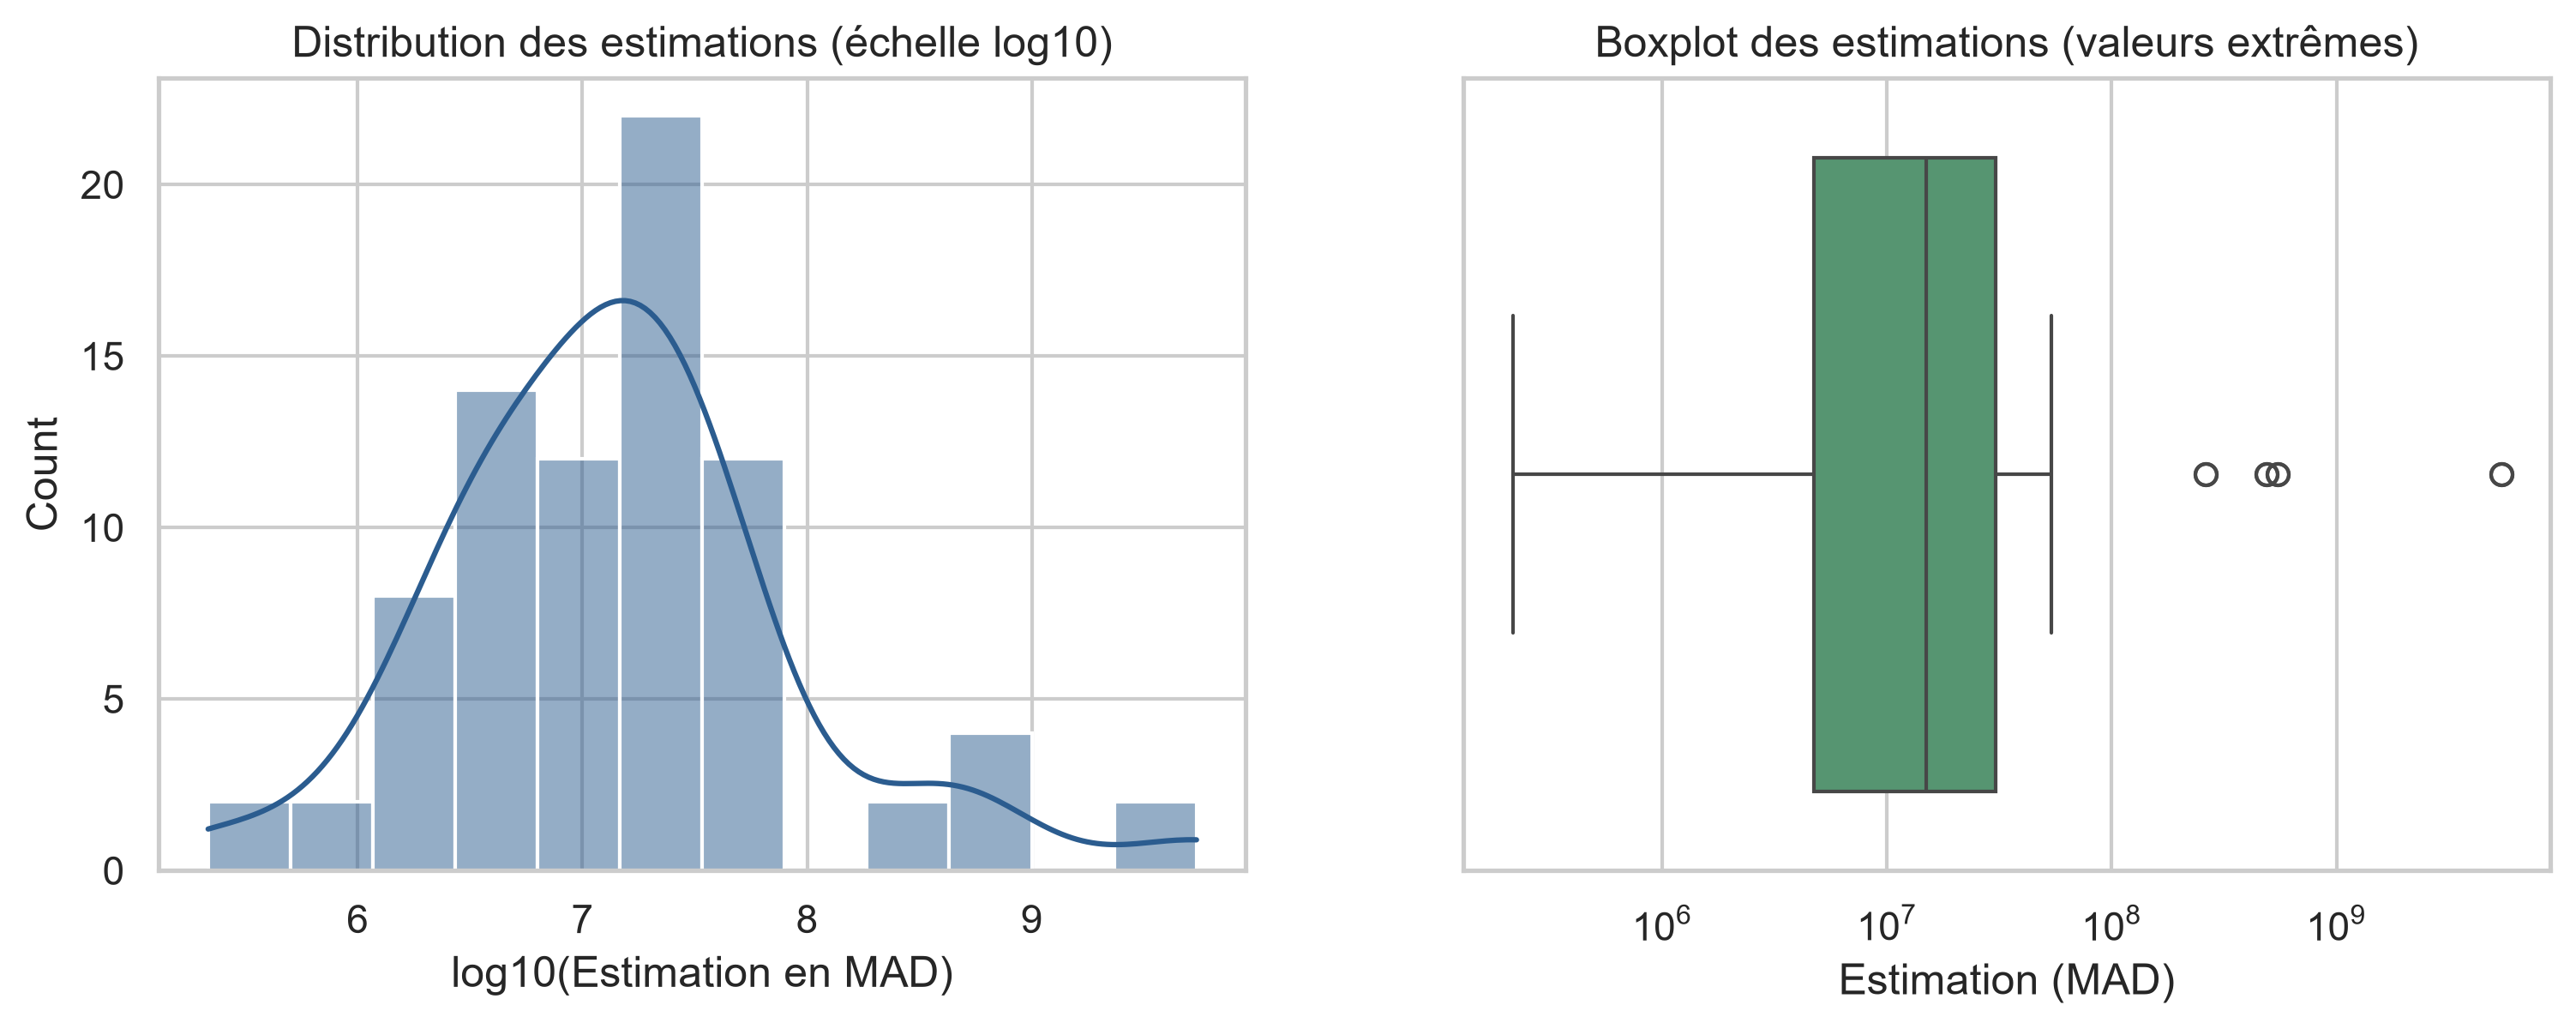

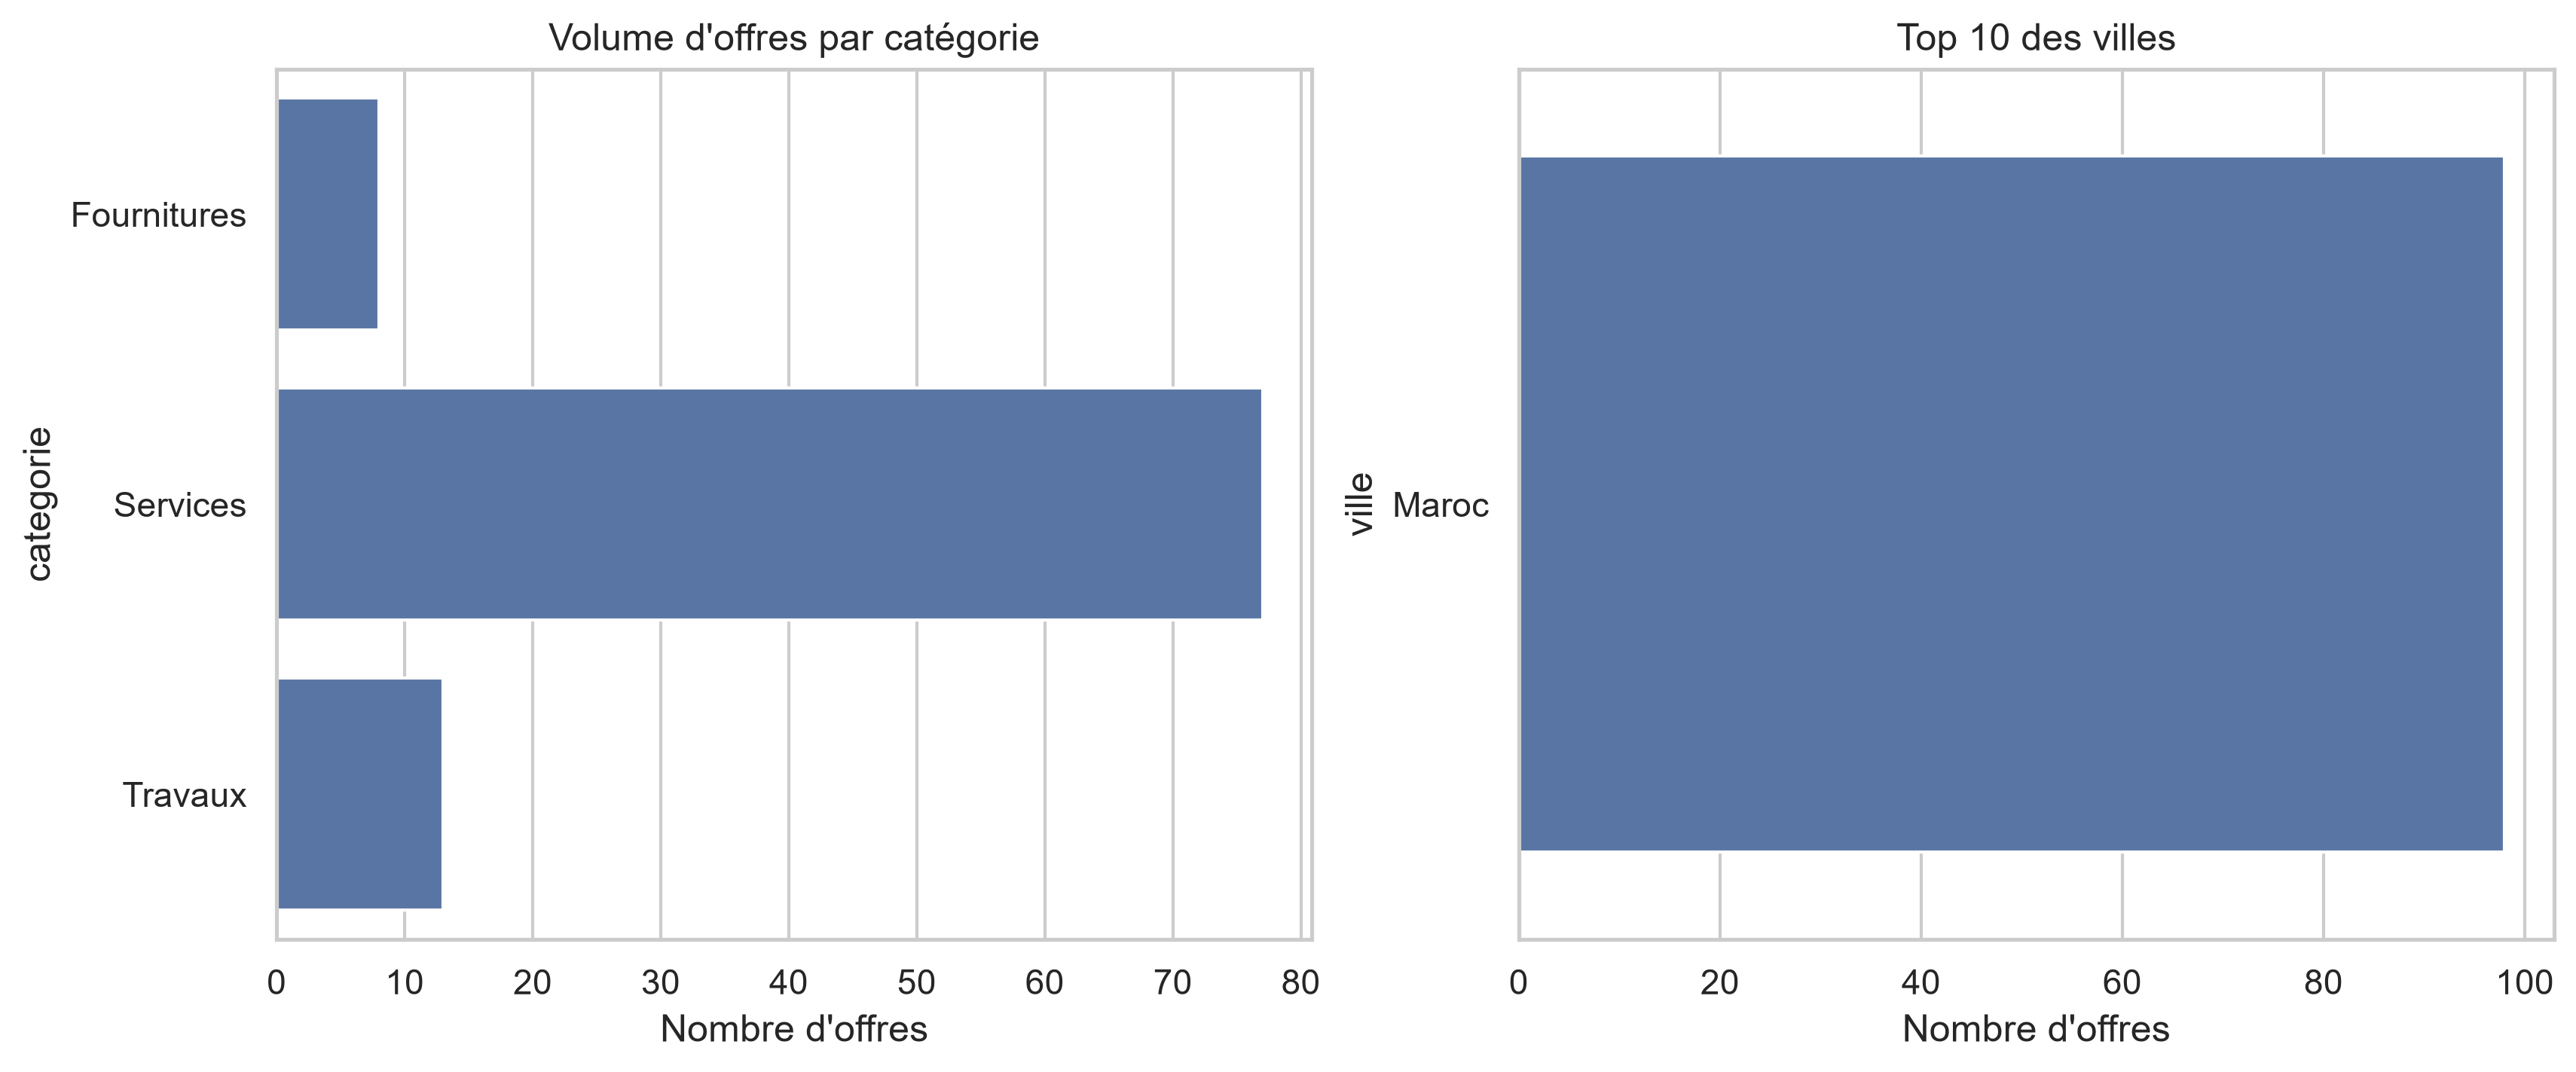

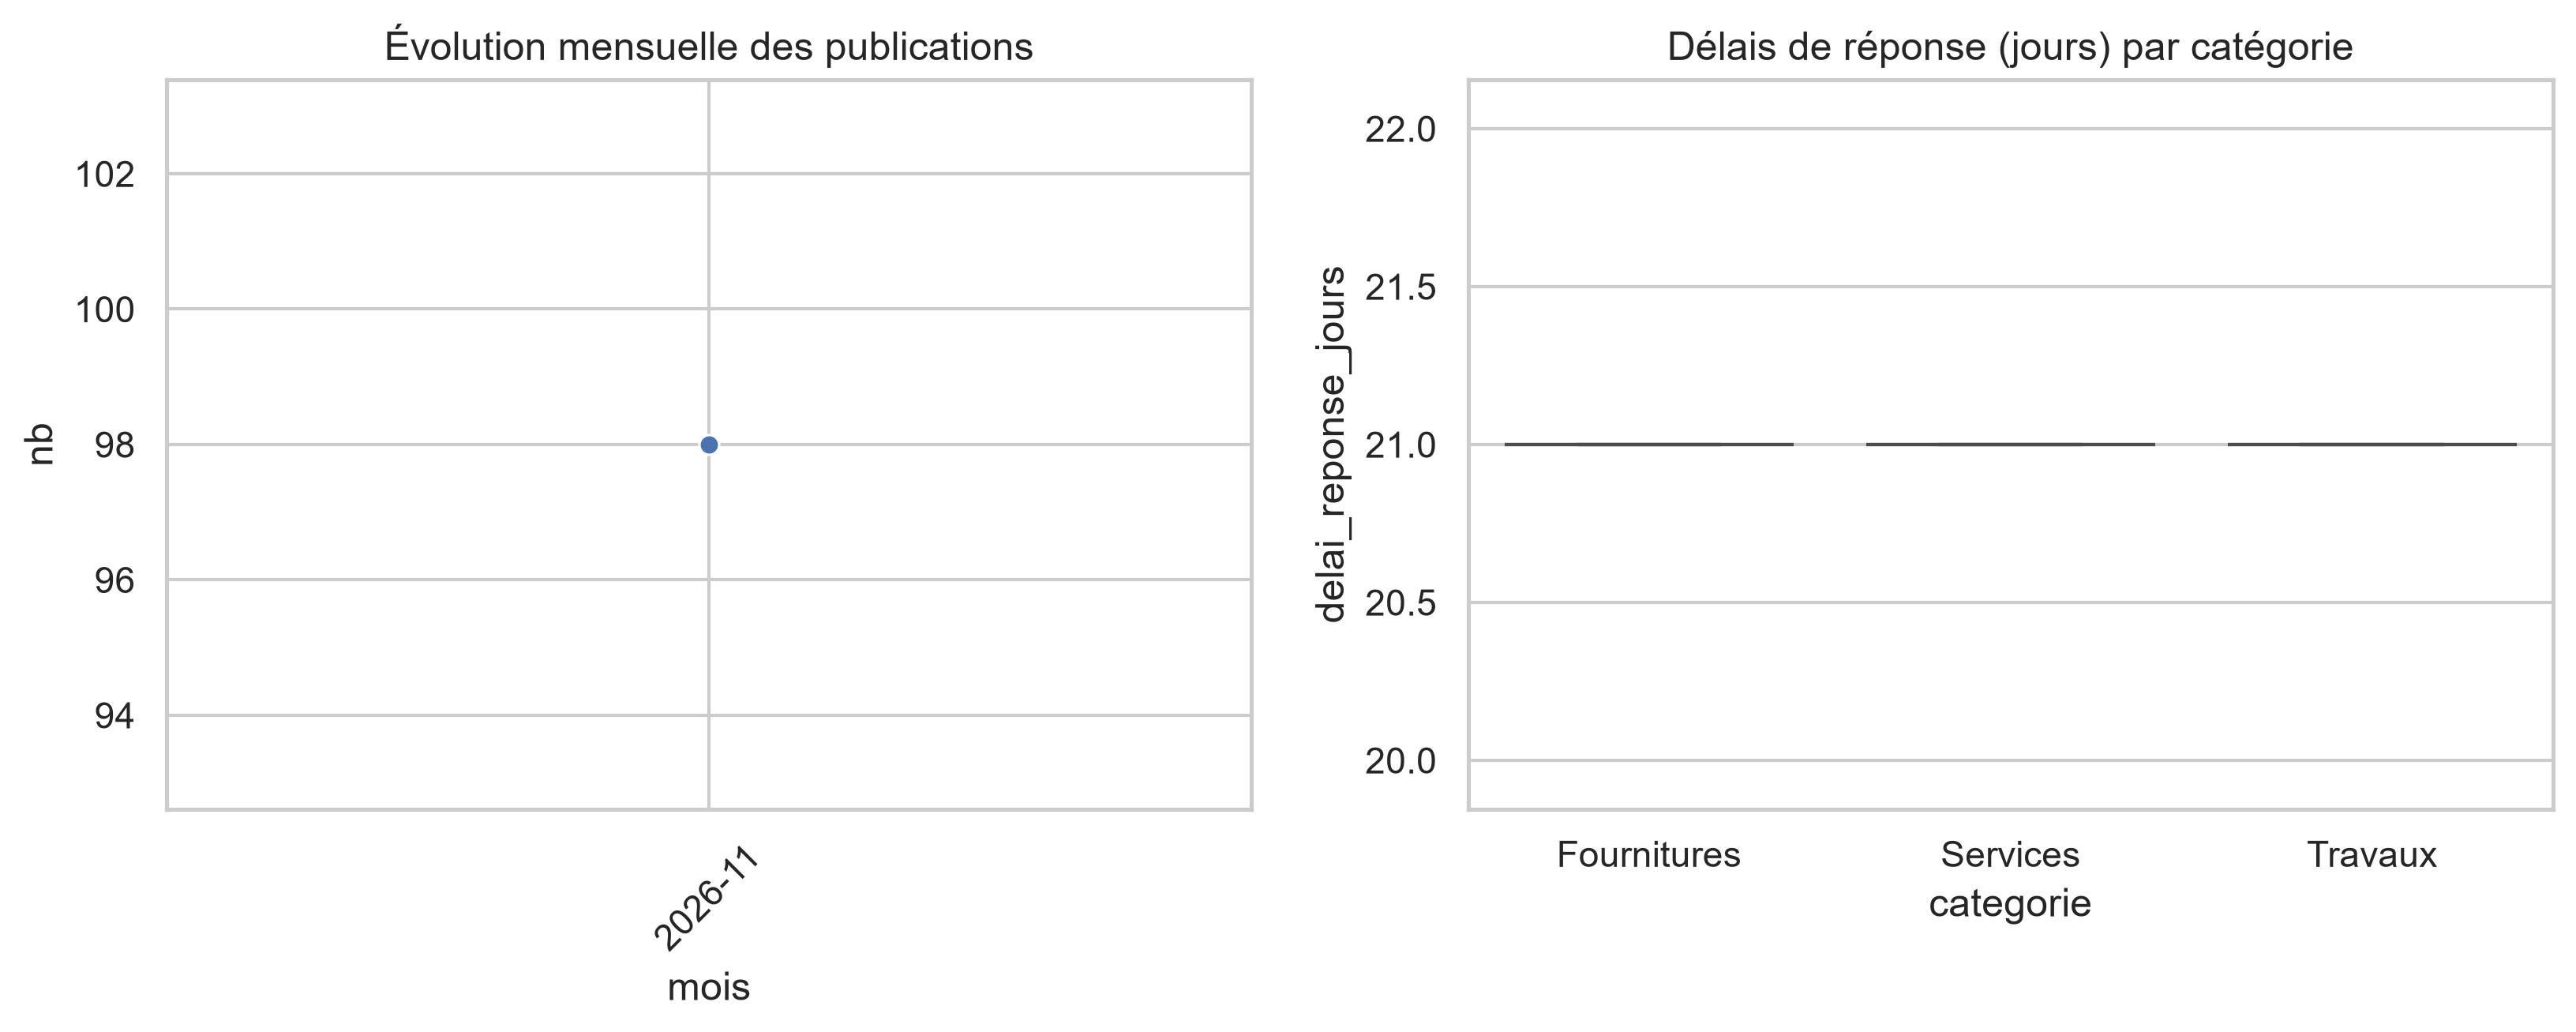

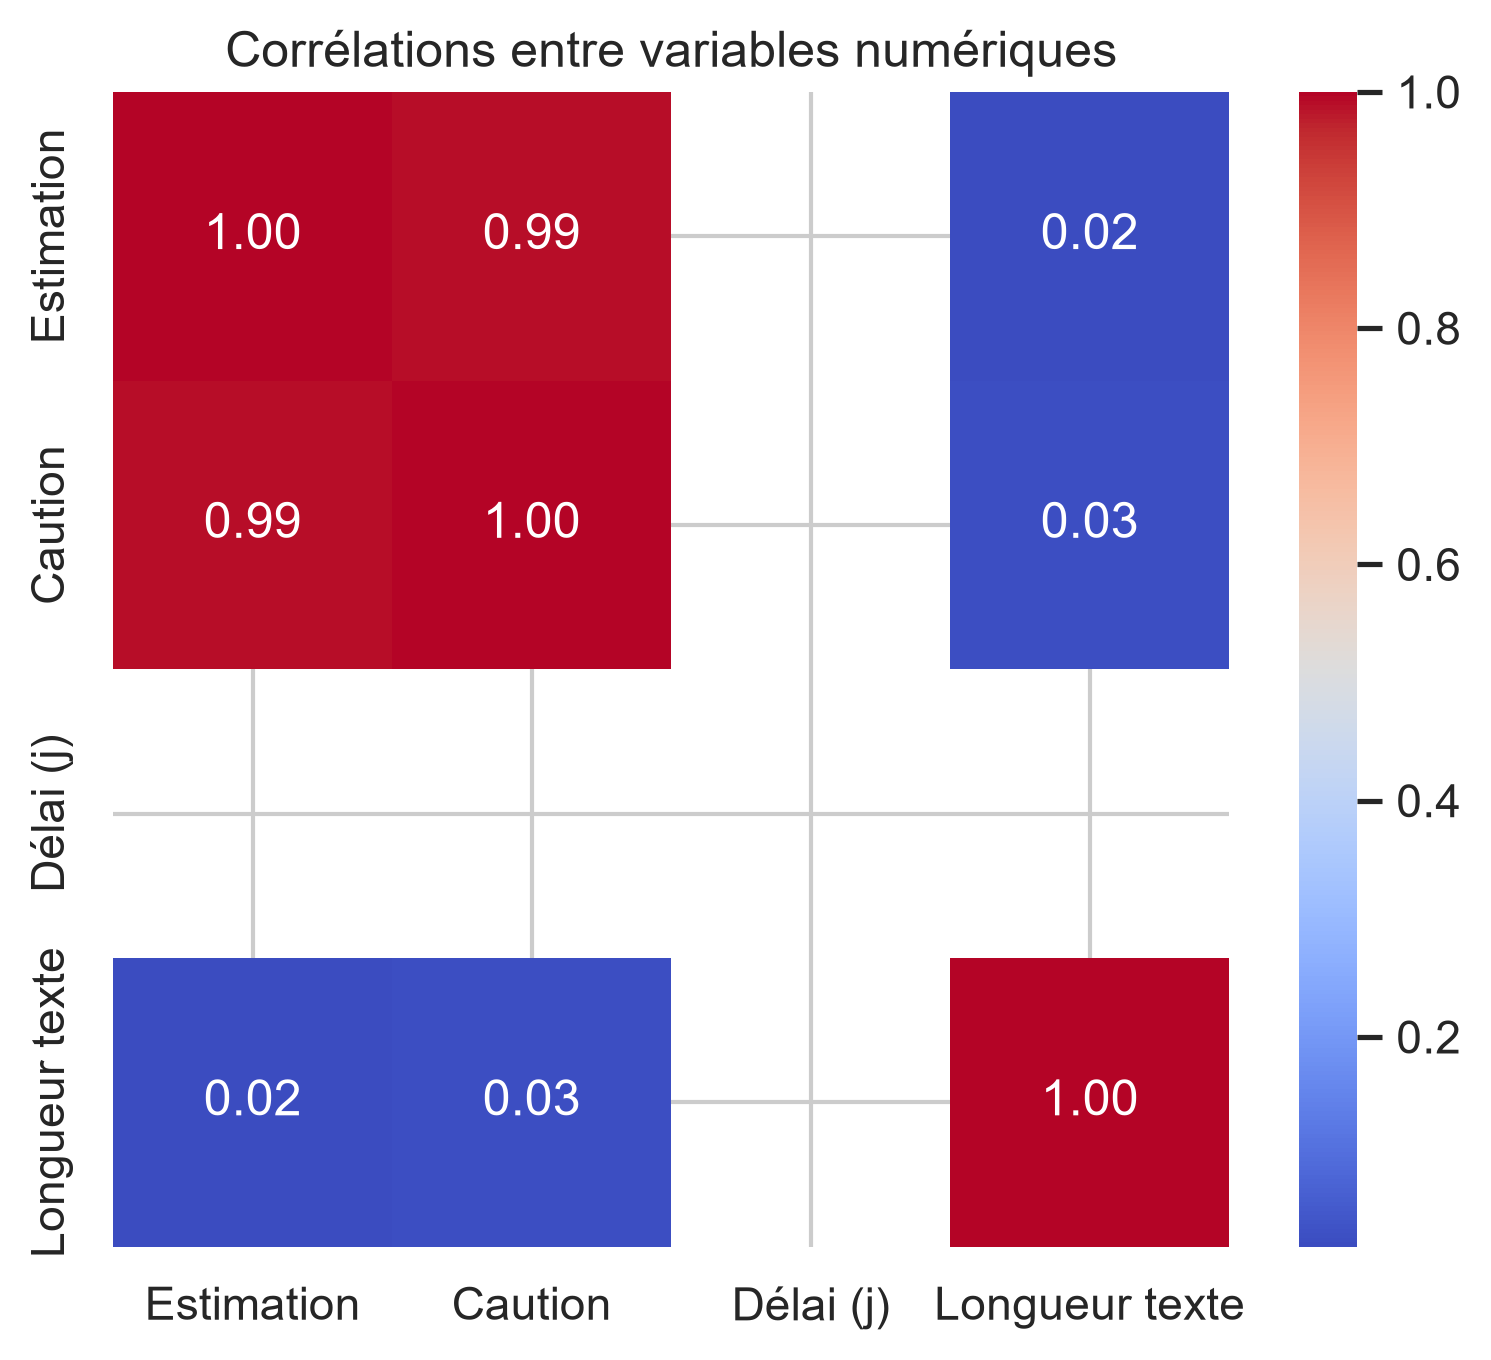

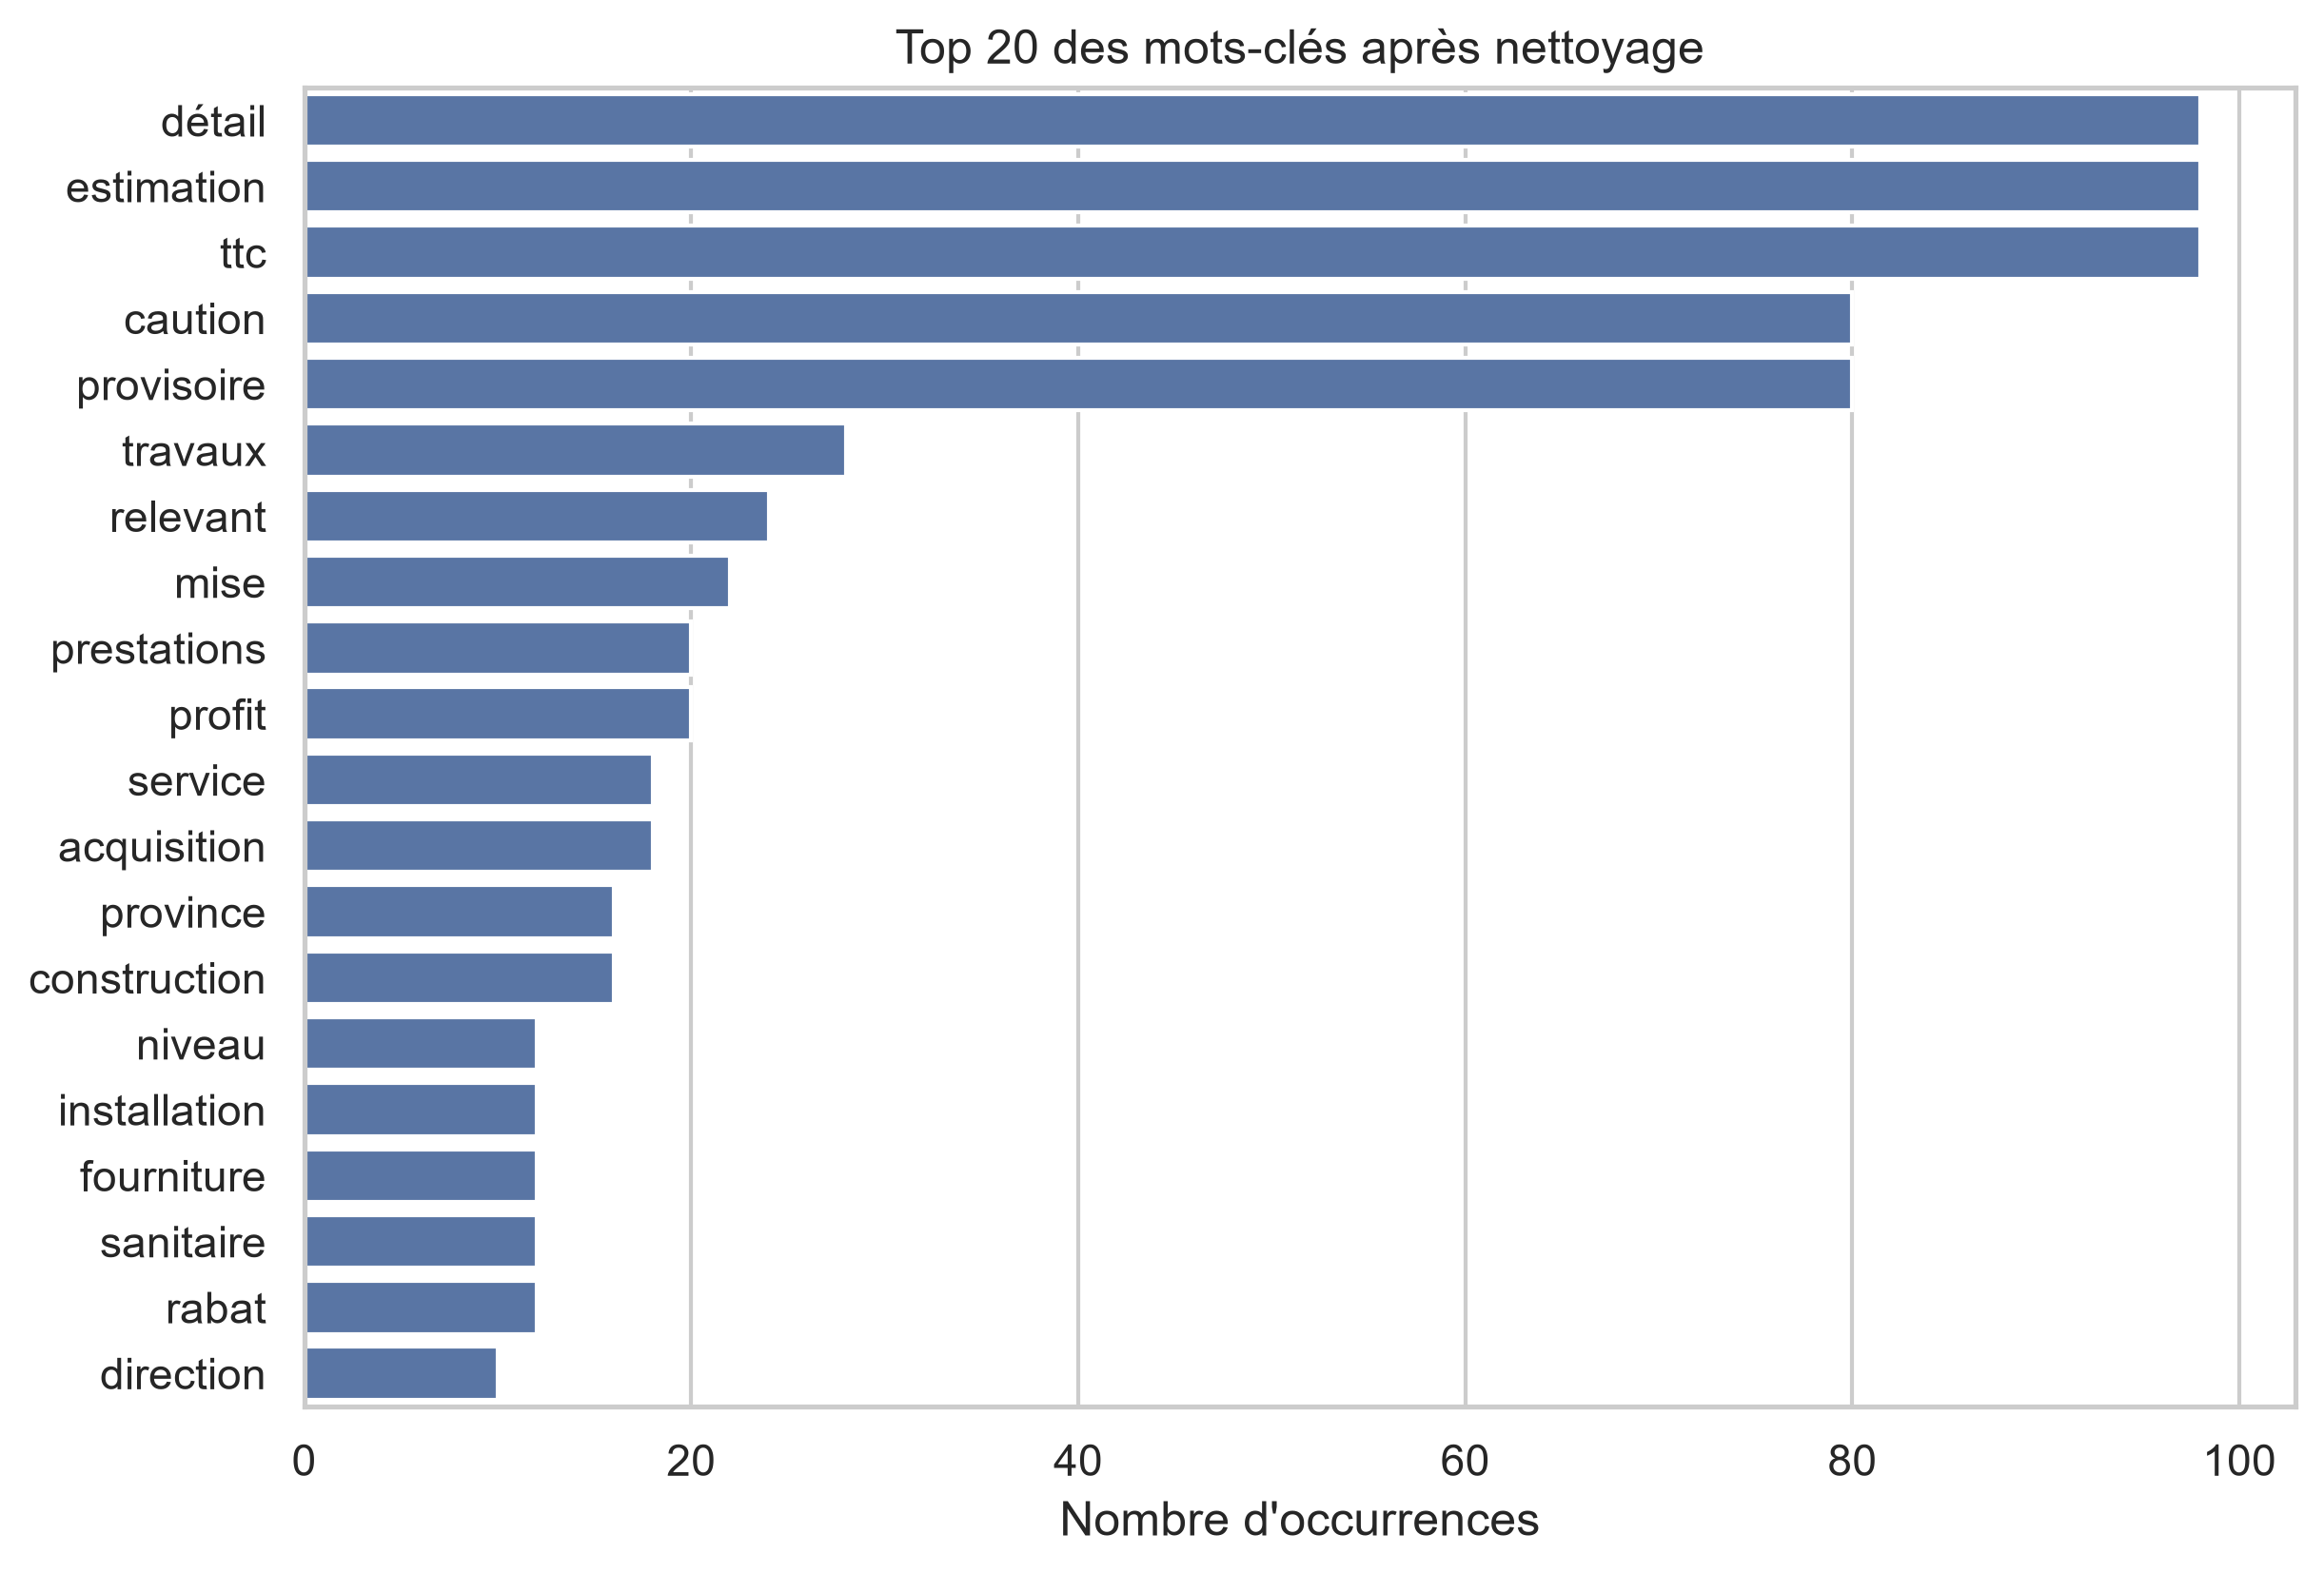

In [4]:
resume_statistique(df_clean)
for fig_path in generer_graphiques(df_clean, dossier_sortie="../reports/figures"):
    display(Image(filename=str(fig_path)))